# TP2 : Extraction d'information – Le Soir en 1960

**Cours :** Traitement automatique de corpus (STIC-B545)

Ce notebook reprend toutes les étapes du TP2 dans l'ordre :
1. l'extraction de mots clés avec Yake ;
2. le nuage de mots, avec une liste de stopwords enrichie ;
3. la reconnaissance d'entités nommées avec SpaCy ;
4. l'analyse de sentiment de 10 phrases avec TextBlob et BERT.

Les quatre parties viennent des notebooks `s1_keywords`, `s2_wordcloud`, `s3_ner` et `s4_sentiment` du même dossier. Nous les avons d'abord travaillés séparément, puis nous les avons réunis ici.

**Pourquoi 1960 ?** Nous avons choisi cette année pour trois raisons. D'abord, c'est une année très riche pour la Belgique : le Congo devient indépendant le 30 juin, puis une crise éclate. Ensuite, la fin de l'année est marquée par le projet de « loi unique » et par le mariage du roi Baudouin. Enfin, le corpus contient 100 fichiers pour 1960 et ils couvrent les 12 mois. L'année est donc bien représentée.

**Données.** Les fichiers texte du corpus CAMille se trouvent dans `tac/data/txt`. Le dossier `data` n'est pas publié sur GitHub, car il est trop lourd.

# Partie 1 : Extraction de mots clés

Par rapport au notebook du cours, nous avons changé deux choses :
- le chemin vers les données, car le notebook se trouve maintenant dans `tps/tp2` ;
- la liste des fichiers, car nous gardons seulement ceux de 1960.

## Imports

In [1]:
import os
from collections import Counter
import yake

## Extraire les mots clés d'un document avec Yake

https://github.com/LIAAD/yake

In [2]:
# Instantier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

In [3]:
# Choisir une année
year = 1960

In [4]:
# Lister les fichiers de l'année choisie
# Le motif "_1960-" correspond à la date dans le nom du fichier (ex: KB_JB838_1960-01-10_01-00018.txt)
data_path = "../../data/txt/"
files = sorted([f for f in os.listdir(data_path) if f.endswith('.txt') and f"_{year}-" in f])

Nous cherchons le motif `_1960-` et pas seulement `1960`. En effet, ce motif correspond à la date dans le nom du fichier. Nous évitons ainsi de prendre un fichier d'une autre année qui contiendrait « 1960 » ailleurs dans son nom.

In [5]:
# Imprimer le nombre de fichiers identifiés
len(files)

100

In [6]:
# Les dix premiers fichiers
files[:10]

['KB_JB838_1960-01-10_01-00018.txt',
 'KB_JB838_1960-01-12_01-00011.txt',
 'KB_JB838_1960-01-13_01-00009.txt',
 'KB_JB838_1960-01-21_01-00014.txt',
 'KB_JB838_1960-01-22_01-00015.txt',
 'KB_JB838_1960-01-27_01-00006.txt',
 'KB_JB838_1960-01-28_01-00011.txt',
 'KB_JB838_1960-01-28_01-00021.txt',
 'KB_JB838_1960-01-30_01-00007.txt',
 'KB_JB838_1960-01-31_01-00024.txt']

Nous choisissons la première page du journal du 10 juillet 1960. Cette date tombe dix jours après l'indépendance du Congo, donc nous nous attendons à y trouver des mots clés liés à cet événement.

In [7]:
# Choisir un fichier
this_file = "KB_JB838_1960-07-10_01-00001.txt"
this_file in files

True

In [8]:
# Récupérer le texte du fichier
text = open(os.path.join(data_path, this_file), 'r', encoding='utf-8').read()
text[:500]

'74* ANNEE — N" 165 t • • JOURNAL QUOTIDIEN 24 Pages - 2 fr. Congo 4 It. Tronc* r N. F. 0 h. 30 — Sults* l 0 Ir. 40 triste» , CHEQUES POSTAUX PUBLICITE t Compte n* 567S ftOSSEL & C 1 * VENTE I Soit et Soir llluilri ! 14686 Rossel JC" PONS aux Œuvre» du Soit t 14232 Rossel & C" les manuscrits non Insérés ne sont pas rendus LE t AGENCE ROSSEL - Annonces et Publicité LE SOIR - Vente et Abonnements i BRUXELLES I t* 112, rue Royale. 112 PARIS (8\'t t 73. r. d\'Anjou. T. EURope 36.16 PLACE DE LOUVAIN, 21'

In [9]:
# Extraire les mots clés de ce texte
keywords = kw_extractor.extract_keywords(text)
keywords

[('Congo', np.float64(0.011459400532906791)),
 ('belges', np.float64(0.017069287223451187)),
 ('loi belge', np.float64(0.020033090513464708)),
 ('belge', np.float64(0.020862462161995894)),
 ('Force publique', np.float64(0.021580863157646284)),
 ('FORCES BELGES', np.float64(0.02226620235853606)),
 ('troupes belges', np.float64(0.022746122969216475)),
 ('Elisabethville', np.float64(0.02479200991256395)),
 ('gouvernement', np.float64(0.02504215288323947)),
 ('FORCES BELGES IHIIRVIEMHEHT', np.float64(0.02648155097544798)),
 ('qu’il', np.float64(0.029938688471765413)),
 ('Congo belge', np.float64(0.03105856165079044)),
 ('JOURNAL QUOTIDIEN', np.float64(0.032037844002974915)),
 ('forces belges aurait', np.float64(0.03250291290386069)),
 ('loi', np.float64(0.03354842151402469)),
 ('Katanga', np.float64(0.03464835253062551)),
 ('BRUXELLES', np.float64(0.03943590688125622)),
 ('soldats', np.float64(0.039737260840907784)),
 ('troupes', np.float64(0.04252677075634702)),
 ('DIMANCHE', np.float64(0

In [10]:
# Ne garder que les bigrammes
kept = []
for kw, score in keywords:
    words = kw.split()
    if len(words) == 2:
        kept.append(kw)
kept

['loi belge',
 'Force publique',
 'FORCES BELGES',
 'troupes belges',
 'Congo belge',
 'JOURNAL QUOTIDIEN',
 'Société libre',
 'soldats belges',
 'qu’il faut']

**Commentaire.** Les bigrammes de cette page parlent presque tous du même sujet : « Force publique », « troupes belges », « soldats belges », « Congo belge ». La page raconte donc l'envoi de soldats belges au Congo après la révolte de l'armée congolaise. Yake résume bien le thème de la page. En revanche, il garde aussi des expressions sans intérêt comme « journal quotidien », car elles sont imprimées dans l'en-tête du journal.

## Faire la même opération sur tous les documents de l'année

In [11]:
# On garde les bigrammes de chaque fichier dans un dictionnaire pour pouvoir les compter ensuite
keywords_by_file = {}
for f in files:
    text = open(os.path.join(data_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    keywords_by_file[f] = kept
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1960-01-10_01-00018.txt mentions these keywords: Agence Rossel, l’Agence Rossel, Ecrire Agence, Faire offre, Rossel num, IMPORTANTE SOCIETE, Importante firme, BRUXELLES CHERCHE, Importante société, Firme Importante, curriculum vitae, offre manuscrite, vltae Agence...


KB_JB838_1960-01-12_01-00011.txt mentions these keywords: Van den, Van der, classements officiels, Coq Anglais, Van Houtte, Country Club, Léopold Club, Van Blesebroeck, Astrld Club, Van Belle, Baudouin Club...


KB_JB838_1960-01-13_01-00009.txt mentions these keywords: VAN LOOY, Van Stcenbergen, Rik Van, DIVISION III, Fort Jaco, Grand Prix, grand temps, Dimanche division, dimanche dernier...


KB_JB838_1960-01-21_01-00014.txt mentions these keywords: chemise lavée, CHEMISES LAVÉES, Office Propriétaires, Propriétaires Tél, WATERLOO TéL, maison rapport, belle maison, PRIX TARIF, francs Office, bonne maison...


KB_JB838_1960-01-22_01-00015.txt mentions these keywords: LOUER App, Pastilles Antibiotiques, FER FORGE, spac. app, Pet. app...


KB_JB838_1960-01-27_01-00006.txt mentions these keywords: Commerce extérieur, Haute Autorité, Marché commun, politique scientifique, Commission scientifique, recherche scientifique, Conseil national...
KB_JB838_1960-01-28_01-00011.txt mentions these keywords: tient natl, male cho, isent ntàe, prèa date, date ture, ntàe dual, SUPPLÉMENT PARAISSANT, sap anb, Bjua sap, Bagoa sap, Bap oun, sauiuioq sap, jx’ÎV'S Ocsr, Banapioa xnu, xnofjq sap, uaiq anb...


... (79 outputs left out)

KB_JB838_1960-12-06_01-00011.txt mentions these keywords: Grand Prix, derby Anderlecht, Van Kerrebroek, willy Mairesse, Mairesse fit, Van Geel...


KB_JB838_1960-12-10_01-00019.txt mentions these keywords: Biscuits Rem, Biscuiterie Alsacienne, Alsacienne Confiserie, Charcuterie Alsacienne, Alsacienne Fincker, Artus Biscuits, Amieux Rivoir, Carret Chocolat, Chocolat Cemoi, Cemoi Biscottes, Biscottes Darry, Darry Alsaglace, Alsaglace Feyel, Feyel Cassegrain, Rem Biscuiterie, Jaumart Charcuterie, Marquise Amora, Battendî.er Mîlliat, Mîlliat Frères...


KB_JB838_1960-12-21_01-00017.txt mentions these keywords: Ets BRACONNIER, BRACONNIER Siège, Agence Rossel, Rossel num, Ecrire Agence, Siège central, DACTYLO BILINGUE, Agença Rossel, Bruxelles dem, STENO DACTYLO...


KB_JB838_1960-12-23_01-00019.txt mentions these keywords: l'Agence Rossel, som Moment, Moment critique, Rossel num, Agence Rossel, Importante firme, service militaire, entrée immédiate, Firme dem, demande VENDEUR, critique dons, place demande, IMPORTANTE MAISON...


## Compter les mots clés qui reviennent dans plusieurs documents

La liste ci-dessus est longue, donc elle est difficile à lire. Nous comptons alors dans combien de fichiers chaque bigramme apparaît. Cela montre les sujets qui reviennent le plus souvent pendant l'année.

In [12]:
# Pour chaque bigramme, compter dans combien de fichiers de l'année il apparaît
counter = Counter()
for f, kws in keywords_by_file.items():
    counter.update(set(kw.lower() for kw in kws))

for kw, n in counter.most_common(40):
    print(f"{kw} : {n} fichiers")

agence rossel : 17 fichiers
ecrire agence : 11 fichiers
rossel num : 9 fichiers
l’agence rossel : 9 fichiers
dem. fem : 7 fichiers
faire offre : 6 fichiers
van den : 6 fichiers
van looy : 6 fichiers
congo belge : 6 fichiers
new york : 6 fichiers
bruxelles tél : 6 fichiers
importante firme : 5 fichiers
demeurant rue : 5 fichiers
bruxelles demande : 5 fichiers
curriculum vitae : 4 fichiers
rik van : 4 fichiers
grand prix : 4 fichiers
opel rek : 4 fichiers
journal quotidien : 4 fichiers
habitant rue : 4 fichiers
bruxelles dem : 4 fichiers
bel app : 4 fichiers
nations unies : 4 fichiers
offre manuscrite : 3 fichiers
division iii : 3 fichiers
propriétaires tél : 3 fichiers
bonne maison : 3 fichiers
marché commun : 3 fichiers
rue van : 3 fichiers
soir mercredi : 3 fichiers
conseil communal : 3 fichiers
d’une fracture : 3 fichiers
bon salaire : 3 fichiers
jeune homme : 3 fichiers
domicilié rue : 3 fichiers
reine elisabeth : 3 fichiers
lundi matin : 3 fichiers
servante int : 3 fichiers
gouvern

**Commentaire.** Trois groupes de mots clés ressortent.

1. **Les petites annonces.** « Agence Rossel » apparaît dans 17 fichiers sur 100, donc dans près d'une page sur cinq. « Ecrire agence », « faire offre » et « curriculum vitae » vont dans le même sens. Ces mots viennent des pages d'offres d'emploi. Ils sont fréquents, mais ils ne disent rien sur l'actualité de 1960. Nous devrons donc les retirer pour le nuage de mots.
2. **L'actualité politique.** « Congo belge » et « New York » apparaissent chacun dans 6 fichiers, « Nations Unies » dans 4, « gouvernement belge » et « marché commun » dans 3. Le Congo est donc le sujet d'actualité le plus présent. De plus, « New York » et « Nations Unies » montrent que la crise congolaise se discute aussi à l'ONU.
3. **Le sport.** « Van Looy » apparaît dans 6 fichiers et « Rik Van » dans 4. Il s'agit du coureur cycliste Rik Van Looy, qui est alors une vedette en Belgique. « Grand prix » (4 fichiers) confirme la place du sport dans le journal.

**Limites.** Certains bigrammes n'ont pas de sens, par exemple « van den » ou « rue van ». Ce sont des morceaux de noms flamands. D'autres sont déformés par l'OCR, par exemple « vltae agence ». Les résultats de Yake doivent donc être relus avant d'être interprétés.

# Partie 2 : Nuage de mots

Ce notebook crée un nuage de mots pour l'année 1960. Nous gardons la fonction `clean_text` du cours sans la modifier. Nous changeons seulement trois choses : l'année, le chemin vers les données et la liste de stopwords. Cette liste est enrichie en trois étapes, car chaque étape fait apparaître de nouveaux mots inutiles.

## Imports et stopwords

In [13]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to C:\Users\COMPUTER
[nltk_data]     STORES\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [14]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
sw = set(sw)
len(sw)

200

## Créer un fichier contenant le texte de tous les journaux d'une année donnée

In [15]:
# Choisir une année
year = 1960

In [16]:
# Lister les fichiers de cette année
# Le motif "_1960-" vise la date dans le nom du fichier
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and f"_{year}-" in f]
len(txts)

100

In [17]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [18]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [19]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

"ia« le som ÏJsIne MéuhMrïiqii S.AT'BBirîï^^ J00, r. Merlu» Duché, Vllvorde ch. STENO-DACTYLO élément de let ordre, bilingue, bon- i ne rémunération. Situation d’avenir, i Candidat, A soumet par écrit "

In [20]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [21]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

'ia« le som ÏJsIne MéuhMrïiqii S.AT\'BBirîï^^ J00, r. Merlu» Duché, Vllvorde ch. STENO-DACTYLO élément de let ordre, bilingue, bon- i ne rémunération. Situation d’avenir, i Candidat, A soumet par écrit 130221H PORTANTE 80C.BRUXELL0I8I cherche pour entrée Immédiate Secrétaire Sténo-Dactylo 3 françalee - 1 an d\'expérience, al tuât h «table - semaine de 5 Jours. Ecrire é cur. vit et prêt Ag. Rossel 02983 H "âociËTS\'Importante de sa pi* demande 1 Sténo-Dactylo bilingue débutante. - Se présenter : 151.'

## Nettoyer le fichier à l'aide d'une fonction de nettoyage

### Créer la fonction de nettoyage (à adapter)

In [22]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

### Appliquer la fonction sur le fichier complet de l'année

In [23]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1960_clean.txt!'

In [24]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'SOM ÏJSINE MÉUHMRÏIQII BBIRÎÏ MERLU DUCHÉ VLLVORDE STENO DACTYLO ÉLÉMENT LET ORDRE BILINGUE BON RÉMUNÉRATION SITUATION AVENIR CANDIDAT SOUMET ÉCRIT PORTANTE CHERCHE ENTRÉE IMMÉDIATE SECRÉTAIRE STÉNO DACTYLO FRANÇALEE EXPÉRIENCE TUÂT TABLE SEMAINE JOURS ECRIRE CUR VIT PRÊT ÂOCIËTS IMPORTANTE DEMANDE STÉNO DACTYLO BILINGUE DÉBUTANTE PRÉSENTER RUE STALLE UCCLE IMPORTANTE CLE DELCO ASSURANCES DEMANDE INSPECTEUR PRODUCTEUR ACELDENTE INEENDLE VIE AGE ANS RÉSIDENCE OBLIGATOIRE AJOST AUDENAERDE ENVIRONS'

## Enrichir la liste de stopwords de manière itérative

### Itération 0 : la liste de départ

Nous regardons d'abord les mots les plus fréquents avec la liste de stopwords du cours (200 mots).

In [25]:
frequencies = Counter(after.split())
print(len(after.split()), "mots gardés")
print(frequencies.most_common(40))

277147 mots gardés
[('RUE', 1563), ('TÉL', 1204), ('BRUXELLES', 1112), ('ANS', 796), ('PRIX', 590), ('TRÈS', 545), ('BON', 466), ('APP', 451), ('DEMANDE', 426), ('PLACE', 412), ('ECR', 394), ('PRÉS', 387), ('BRUX', 386), ('GRAND', 384), ('SOIR', 379), ('ECRIRE', 374), ('MAISON', 357), ('BELGIQUE', 346), ('AGENCE', 343), ('BELGE', 333), ('HEURES', 330), ('PART', 328), ('TEMPS', 327), ('COURS', 317), ('MOIS', 304), ('AVANT', 296), ('CONGO', 294), ('BONNE', 293), ('PEU', 291), ('TRAV', 290), ('FRANCS', 288), ('TOUTE', 282), ('QUELQUES', 281), ('SERVICE', 277), ('PAYS', 277), ('JOURS', 274), ('AVENUE', 271), ('ANVERS', 270), ('LEURS', 269), ('PREMIÈRE', 266)]


**Commentaire.** Avec la liste de départ, il reste 277 147 mots. Les mots les plus fréquents sont « RUE » (1 563 fois), « TÉL » (1 204 fois) et « BRUXELLES » (1 112 fois). Ces mots viennent des adresses et des petites annonces. Ils cachent donc l'actualité : le premier mot vraiment lié à 1960, « CONGO », arrive seulement en 27e position avec 294 occurrences. Un nuage de mots construit maintenant montrerait surtout des annonces. Il faut donc enrichir la liste.

### Itération 1 : les abréviations et le vocabulaire des petites annonces

In [26]:
sw_annonces = ["tél", "tel", "téléph", "téléphone", "ecr", "ecrire", "écrire", "app", "appart", "brux", "trav", "enf",
       "mod", "fem", "culs", "vis", "conf", "réf", "référ", "références", "mat", "rem", "gar", "bat",
       "bur", "bel", "mén", "pers", "jne", "adr", "pet", "faç", "chf", "com", "int", "sem",
       "serv", "ouvr", "vend", "aven", "jrs", "jard", "ena", "num", "rez", "cuis", "sam", "frs",
       "terr", "sup", "sal", "ter", "comm", "grd", "den", "apr", "con", "pts", "lux", "vitae",
       "curriculum", "agence", "soir", "rue", "avenue", "chaussée", "étage", "prix", "francs", "offre", "demande", "cherche",
       "louer", "vendre", "vente", "ventes", "présenter", "adresser", "dactylo", "bilingue", "firme", "occasion", "conditions", "servante",
       "serveuse", "emploi", "personnel", "atelier", "garage", "villa", "auto", "notaire", "demeurant", "habitant", "stable", "satisfaction"]
sw |= set(sw_annonces)
len(sw)

296

In [27]:
# Itération 1 : nettoyer à nouveau et regarder les mots les plus fréquents
clean_text(year, folder=temp_path)
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()
frequencies = Counter(after.split())
print(len(after.split()), "mots gardés")
print(frequencies.most_common(40))

260064 mots gardés
[('BRUXELLES', 1112), ('ANS', 796), ('TRÈS', 545), ('BON', 466), ('PLACE', 412), ('PRÉS', 387), ('GRAND', 384), ('MAISON', 357), ('BELGIQUE', 346), ('BELGE', 333), ('HEURES', 330), ('PART', 328), ('TEMPS', 327), ('COURS', 317), ('MOIS', 304), ('AVANT', 296), ('CONGO', 294), ('BONNE', 293), ('PEU', 291), ('TOUTE', 282), ('QUELQUES', 281), ('SERVICE', 277), ('PAYS', 277), ('JOURS', 274), ('ANVERS', 270), ('LEURS', 269), ('PREMIÈRE', 266), ('MME', 265), ('JEUNE', 264), ('JEAN', 258), ('MIDI', 253), ('TRAVAIL', 251), ('PREMIER', 250), ('LIBRE', 247), ('DIMANCHE', 247), ('GRANDE', 247), ('SAINT', 247), ('JUILLET', 247), ('SAMEDI', 246), ('DEVANT', 235)]


**Commentaire.** Nous avons ajouté 96 mots et il reste 260 064 mots, soit 17 083 de moins. Les abréviations des annonces ont disparu (« TÉL », « APP », « ECR »). En revanche, la tête du classement contient maintenant des mots très courants comme « ANS », « TRÈS », « BON » ou « GRAND ». Ces mots existent dans tous les textes, donc ils ne décrivent pas l'année 1960.

### Itération 2 : les mots courants sans contenu (adverbes, adjectifs, nombres, jours, mois)

In [28]:
sw_courants = ["ans", "très", "bon", "bonne", "bons", "bonnes", "grand", "grande", "grands", "petit", "petite", "gros",
       "beau", "belle", "peu", "trop", "fort", "mal", "mieux", "assez", "toute", "quelques", "quelque", "plusieurs",
       "chaque", "certains", "aucun", "seul", "seule", "leurs", "celui", "ceux", "elles", "laquelle", "avant", "devant",
       "vers", "chez", "près", "dès", "puis", "alors", "déjà", "toujours", "jamais", "souvent", "également", "enfin",
       "cependant", "parmi", "selon", "lors", "malgré", "surtout", "notamment", "seulement", "beaucoup", "tant", "autant", "quand",
       "parce", "car", "quant", "tandis", "ici", "loin", "tard", "ailleurs", "premier", "première", "deuxième", "troisième",
       "dernier", "dernière", "nouveau", "nouvelle", "quatre", "cinq", "six", "sept", "neuf", "demi", "quart", "cent",
       "temps", "heure", "heures", "jour", "jours", "journée", "matin", "midi", "semaine", "mois", "année", "années",
       "début", "fin", "suite", "partie", "part", "lieu", "place", "point", "vue", "effet", "cas", "cause",
       "raison", "rapport", "ordre", "nombre", "doute", "reste", "mise", "coup", "tour", "moment", "fois", "âge",
       "age", "lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche", "janvier", "février", "mars", "avril",
       "mai", "juin", "juillet", "août", "septembre", "octobre", "novembre", "décembre", "voir", "prendre", "mettre", "partir",
       "vient", "sait", "donné", "pris", "mis", "fit", "semble", "pourrait", "devait", "agit", "voici", "rien",
       "etc", "possible", "présent", "prés", "libre", "importante", "courant", "haut", "bas", "cher", "prêt", "divers",
       "environ", "actuellement", "pourquoi", "hui", "aujourd"]
sw |= set(sw_courants)
len(sw)

469

In [29]:
# Itération 2 : nettoyer à nouveau et regarder les mots les plus fréquents
clean_text(year, folder=temp_path)
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()
frequencies = Counter(after.split())
print(len(after.split()), "mots gardés")
print(frequencies.most_common(40))

232651 mots gardés
[('BRUXELLES', 1112), ('MAISON', 357), ('BELGIQUE', 346), ('BELGE', 333), ('COURS', 317), ('CONGO', 294), ('SERVICE', 277), ('PAYS', 277), ('ANVERS', 270), ('MME', 265), ('JEUNE', 264), ('JEAN', 258), ('TRAVAIL', 251), ('SAINT', 247), ('ÉQUIPE', 223), ('MINISTRE', 217), ('SITUATION', 216), ('FRANCE', 215), ('ÉTAT', 212), ('BELGES', 210), ('CENTRE', 208), ('PARIS', 207), ('GÉNÉRAL', 195), ('FRANÇAIS', 193), ('HOMME', 193), ('GOUVERNEMENT', 191), ('ENFANTS', 187), ('DIVISION', 186), ('PRÉSIDENT', 186), ('LOUISE', 175), ('FEMME', 175), ('LOI', 175), ('VIE', 173), ('BUREAU', 173), ('SOCIÉTÉ', 170), ('VOITURE', 169), ('LIÈGE', 169), ('HOMMES', 165), ('MARCHÉ', 164), ('CONSEIL', 162)]


**Commentaire.** Nous avons ajouté 173 mots courants (adverbes, adjectifs, nombres, jours, mois). Il reste 232 651 mots. Le résultat devient lisible : « BELGIQUE », « BELGE » et « CONGO » sont dans les six premiers. Cependant, « BRUXELLES » reste largement en tête avec 1 112 occurrences, soit trois fois plus que « BELGIQUE » (346). Ce mot vient surtout des adresses, car Le Soir est un journal bruxellois. Il reste aussi des prénoms (« JEAN », « LOUISE ») et des civilités (« MME »).

### Itération 3 : les communes bruxelloises, les civilités et les prénoms

Nous retirons « Bruxelles » et ses communes, car elles viennent des adresses des annonces. Nous retirons aussi les civilités et les prénoms les plus fréquents, car un prénom seul ne permet pas de reconnaître une personne. C'est un choix : nous perdons l'information sur le lieu, mais nous gagnons en lisibilité.

In [30]:
sw_adresses = ["bruxelles", "uccle", "anderlecht", "ixelles", "schaerbeek", "forest", "jette", "mme", "monsieur", "dame", "dames", "homme",
       "hommes", "femme", "fille", "jeune", "jeunes", "jean", "pierre", "louis", "paul", "jacques", "georges", "andré",
       "albert", "marie", "louise", "max", "henri", "robert", "joseph", "saint", "maison", "centre", "service", "bureau",
       "porte", "entrée", "cours", "série", "serie", "iii"]
sw |= set(sw_adresses)
len(sw)

511

In [31]:
# Itération 3 : appliquer le nettoyage final
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1960_clean.txt!'

In [32]:
# Vérifier le résultat final
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'SOM ÏJSINE MÉUHMRÏIQII BBIRÎÏ MERLU DUCHÉ VLLVORDE STENO ÉLÉMENT LET RÉMUNÉRATION SITUATION AVENIR CANDIDAT SOUMET ÉCRIT PORTANTE IMMÉDIATE SECRÉTAIRE STÉNO FRANÇALEE EXPÉRIENCE TUÂT TABLE CUR VIT ÂOCIËTS STÉNO DÉBUTANTE STALLE CLE DELCO ASSURANCES INSPECTEUR PRODUCTEUR ACELDENTE INEENDLE VIE RÉSIDENCE OBLIGATOIRE AJOST AUDENAERDE ENVIRONS APPOINTEMENTS RAIS ROUTE BARÈME RAIS VOITURE JURCOMNILSSLONS SITUATION AVENIR ÉLÉMENT DYNAMIQUE TRAVAILLEUR VLTAE PHARMACIEN DTNDUSTRIE INTÉRIM EED LABORATOIR'

## Nuage de mots

### Afficher les termes les plus fréquents

In [33]:
frequencies = Counter(after.split())
print(len(after.split()), "mots gardés")
print(frequencies.most_common(50))

225519 mots gardés
[('BELGIQUE', 346), ('BELGE', 333), ('CONGO', 294), ('PAYS', 277), ('ANVERS', 270), ('TRAVAIL', 251), ('ÉQUIPE', 223), ('MINISTRE', 217), ('SITUATION', 216), ('FRANCE', 215), ('ÉTAT', 212), ('BELGES', 210), ('PARIS', 207), ('GÉNÉRAL', 195), ('FRANÇAIS', 193), ('GOUVERNEMENT', 191), ('ENFANTS', 187), ('DIVISION', 186), ('PRÉSIDENT', 186), ('LOI', 175), ('VIE', 173), ('SOCIÉTÉ', 170), ('VOITURE', 169), ('LIÈGE', 169), ('MARCHÉ', 164), ('CONSEIL', 162), ('MONDE', 162), ('MILLIONS', 156), ('NAMUR', 155), ('COUR', 150), ('NORD', 149), ('MATCH', 146), ('OUVRIER', 146), ('ROUTE', 145), ('EAU', 145), ('TRAVAUX', 141), ('CHAMBRE', 140), ('AFFAIRES', 139), ('CHEF', 138), ('COMMERCE', 136), ('SALLE', 135), ('MORT', 134), ('FORCE', 133), ('GAND', 133), ('ETAT', 133), ('POLITIQUE', 133), ('VICTOIRE', 129), ('NUIT', 129), ('COURSE', 127), ('AIDE', 125)]


**Commentaire.** La liste finale contient 511 stopwords, contre 200 au départ. Il reste 225 519 mots sur 277 147. Nous avons donc retiré 51 628 mots, soit environ 19 % du texte nettoyé. Ce chiffre est important : près d'un mot sur cinq n'apportait aucune information sur l'année.

Le classement final montre trois thèmes :
- **la politique belge et le Congo** : « BELGIQUE » (346), « BELGE » (333), « CONGO » (294), « MINISTRE » (217), « GOUVERNEMENT » (191). « CONGO » est le troisième mot de l'année. Il passe de la 27e à la 3e place grâce au nettoyage ;
- **le travail et l'économie** : « TRAVAIL » (251), « SOCIÉTÉ » (170), « MARCHÉ » (164), « OUVRIER » (146). Ces mots viennent en partie des offres d'emploi, mais aussi des articles sur les grèves et la loi unique ;
- **le sport** : « ÉQUIPE » (223), « DIVISION » (186), « MATCH » (146), « VICTOIRE » (129).

### Créer, stocker et afficher le nuage de mots

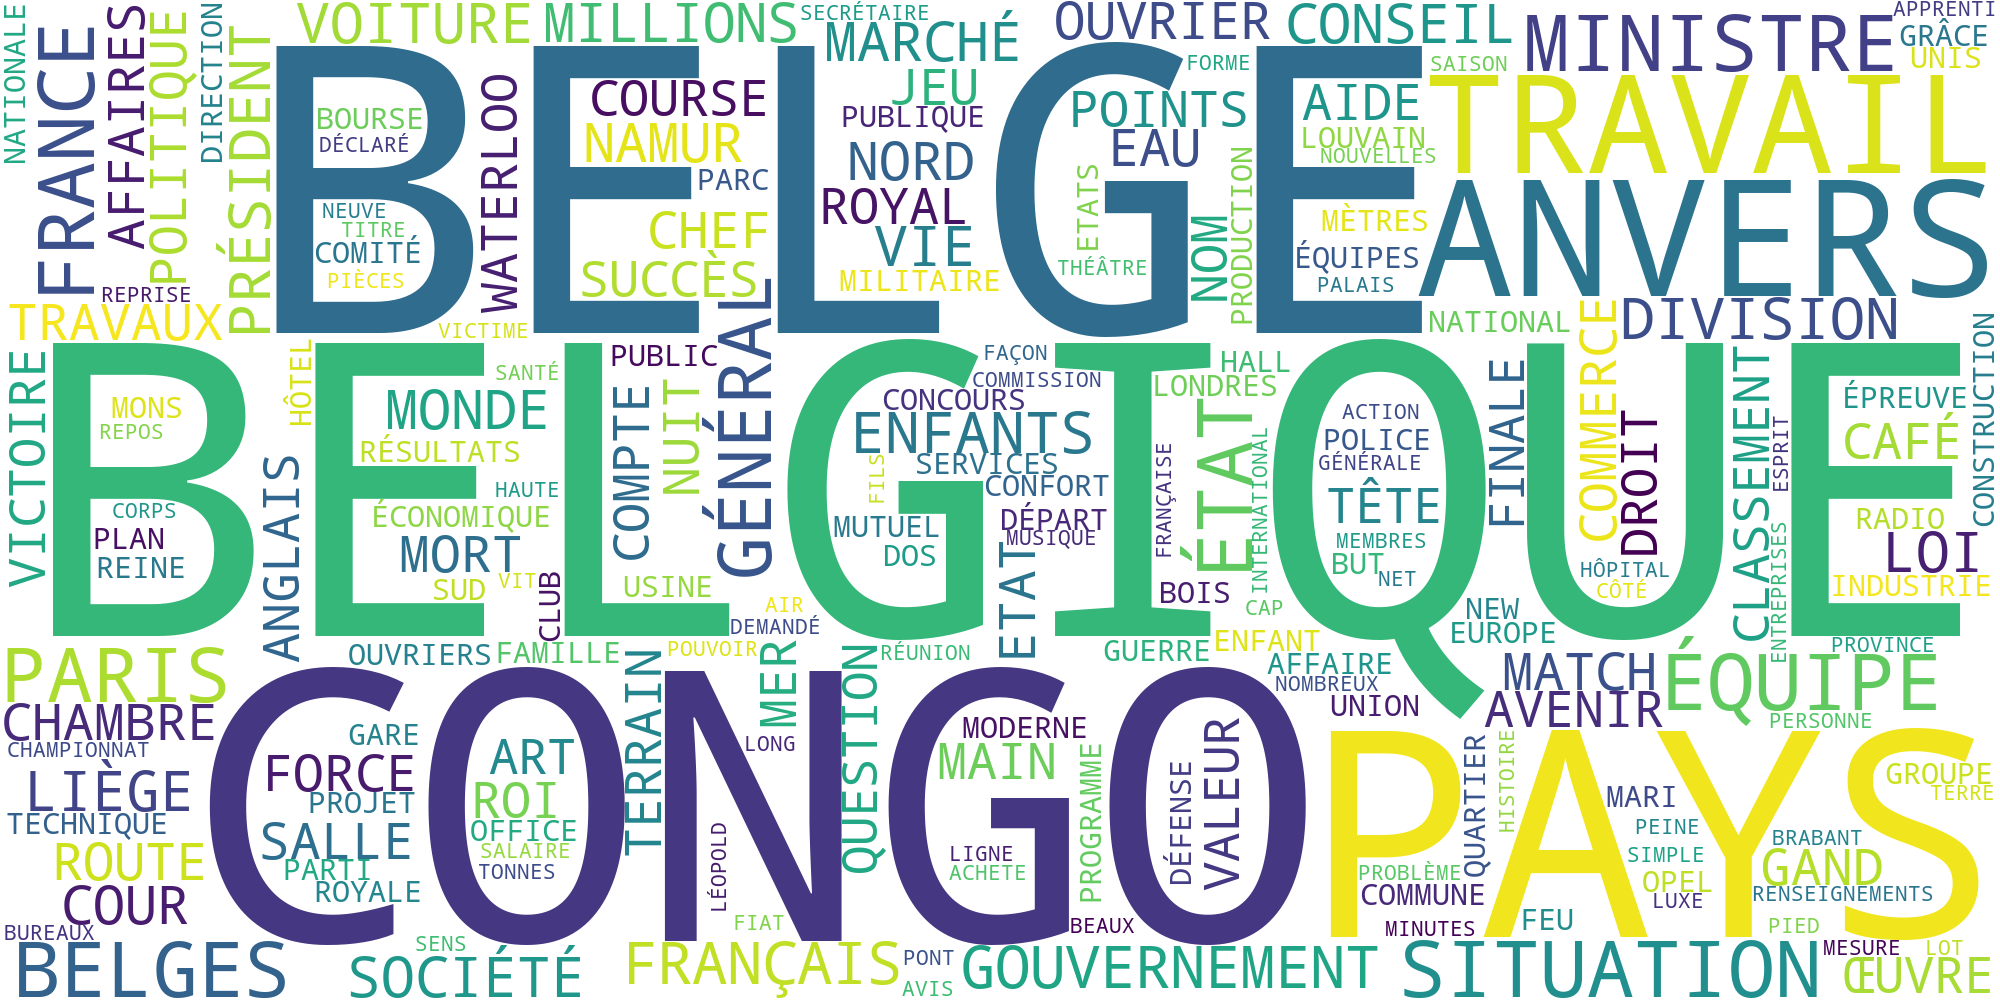

In [34]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

**Commentaire.** Le nuage confirme les chiffres. « BELGIQUE », « BELGE », « CONGO » et « PAYS » sont les plus gros mots. L'année 1960 est donc dominée, dans Le Soir, par la relation entre la Belgique et le Congo. Autour, on lit « GOUVERNEMENT », « MINISTRE », « SITUATION » et « POLITIQUE », qui renvoient à la crise. On lit aussi « TRAVAIL », « ÉQUIPE » et « MATCH », qui rappellent que le journal contient beaucoup d'annonces et de sport.

**Limites.** Certains mots apparaissent en double, par exemple « ÉTAT » et « ETAT », ou « BELGE » et « BELGES ». La fonction `clean_text` ne regroupe pas les formes d'un même mot. De plus, quelques mots viennent encore des annonces (« CONFORT », « LUXE », « OPEL », « FIAT »). Nous pourrions continuer à enrichir la liste, mais le sens général du nuage ne changerait plus.

# Partie 3 : Reconnaissance d'entités nommées

Ce notebook cherche les personnes, les lieux et les organisations les plus cités dans Le Soir en 1960. Comme demandé, nous utilisons le corpus en un seul fichier : `data/tmp/1960.txt`. Ce fichier a été créé dans `s2_wordcloud.ipynb` et il contient les 100 pages de l'année.

Par rapport au notebook du cours, nous avons changé trois choses :
- le texte analysé : toute l'année 1960 au lieu du premier million de caractères de `all.txt` ;
- le découpage du texte en morceaux, car SpaCy refuse les textes trop longs ;
- l'ajout des lieux (LOC) et des organisations (ORG), avec un nettoyage des résultats.

La documentation est accessible ici: https://spacy.io/api

## Imports

In [35]:
from collections import defaultdict
import spacy
from spacy.lang.fr.examples import sentences

In [36]:
nlp = spacy.load('fr_core_news_md')

## Exemple sur un corpus de test fourni par SpaCy

In [37]:
# Imprimer le corpus de Spacy
sentences

['Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars',
 "Les voitures autonomes déplacent la responsabilité de l'assurance vers les constructeurs",
 "San Francisco envisage d'interdire les robots coursiers sur les trottoirs",
 'Londres est une grande ville du Royaume-Uni',
 'L’Italie choisit ArcelorMittal pour reprendre la plus grande aciérie d’Europe',
 "Apple lance HomePod parce qu'il se sent menacé par l'Echo d'Amazon",
 "La France ne devrait pas manquer d'électricité cet été, même en cas de canicule",
 'Nouvelles attaques de Trump contre le maire de Londres',
 'Où es-tu ?',
 'Qui est le président de la France ?',
 'Où est la capitale des États-Unis ?',
 'Quand est né Barack Obama ?']

In [38]:
# Isoler la première phrase
sent = sentences[0]
sent

'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars'

In [39]:
# Traiter la phrase avec Spacy
doc = nlp(sent)

In [40]:
type(doc)

spacy.tokens.doc.Doc

In [41]:
doc.text

'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars'

In [42]:
# Appliquer le test sur toutes les phrases
for sent in sentences:
    doc = nlp(sent)
    entities = []
    for ent in doc.ents:
        entities.append(f"{ent.text} ({ent.label_})")
    if entities:
        print(f"'{doc.text}' contient les entités suivantes : {', '.join(entities)}")
    else:
        print(f"'{doc.text}' ne contient aucune entité")

'Apple cherche à acheter une start-up anglaise pour 1 milliard de dollars' contient les entités suivantes : Apple (ORG)
'Les voitures autonomes déplacent la responsabilité de l'assurance vers les constructeurs' ne contient aucune entité
'San Francisco envisage d'interdire les robots coursiers sur les trottoirs' contient les entités suivantes : San Francisco (LOC)
'Londres est une grande ville du Royaume-Uni' contient les entités suivantes : Londres (LOC), Royaume-Uni (LOC)
'L’Italie choisit ArcelorMittal pour reprendre la plus grande aciérie d’Europe' contient les entités suivantes : L’Italie (LOC), ArcelorMittal (ORG), Europe (LOC)
'Apple lance HomePod parce qu'il se sent menacé par l'Echo d'Amazon' contient les entités suivantes : Apple (ORG), HomePod (MISC), Echo (ORG), Amazon (ORG)
'La France ne devrait pas manquer d'électricité cet été, même en cas de canicule' contient les entités suivantes : La France (LOC)
'Nouvelles attaques de Trump contre le maire de Londres' contient les en

## Appliquer la reconnaissance d'entités nommées sur notre corpus

In [43]:
# Choisir une année
year = 1960

In [44]:
# Charger le texte
# On utilise le corpus de l'année en un seul fichier (créé dans s2_wordcloud.ipynb)
text = open(f"../../data/tmp/{year}.txt", encoding='utf-8').read()
len(text)

3338805

Le texte de 1960 contient 3 338 805 caractères. Or SpaCy accepte au maximum 1 000 000 de caractères à la fois. Nous découpons donc le texte en 34 morceaux. Nous coupons toujours sur un espace, pour ne pas couper un mot ou un nom en deux.

In [45]:
# SpaCy refuse les textes de plus de 1 000 000 de caractères.
# On découpe donc le texte en morceaux de 100 000 caractères environ, en coupant sur un espace.
size = 100000
chunks = []
start = 0
while start < len(text):
    end = min(start + size, len(text))
    if end < len(text):
        space = text.rfind(" ", start, end)
        if space > start:
            end = space
    chunks.append(text[start:end])
    start = end
len(chunks)

34

In [46]:
%%time
# Traiter le texte

docs = list(nlp.pipe(chunks))

CPU times: total: 2min 20s
Wall time: 2min 27s


### Premier essai : compter les entités sans nettoyage

In [47]:
# Compter les entités : personnes (PER), lieux (LOC) et organisations (ORG)
people = defaultdict(int)
locations = defaultdict(int)
organisations = defaultdict(int)
for doc in docs:
    for ent in doc.ents:
        name = " ".join(ent.text.split())
        if len(name) > 3:
            if ent.label_ == "PER":
                people[name] += 1
            elif ent.label_ == "LOC":
                locations[name] += 1
            elif ent.label_ == "ORG":
                organisations[name] += 1

print(f"{len(people)} personnes, {len(locations)} lieux et {len(organisations)} organisations différentes")
print(f"{sum(people.values())} mentions de personnes, {sum(locations.values())} mentions de lieux et {sum(organisations.values())} mentions d'organisations")

16050 personnes, 12863 lieux et 4841 organisations différentes
21091 mentions de personnes, 21552 mentions de lieux et 6672 mentions d'organisations


In [48]:
# Trier et imprimer les personnes (comme dans le notebook du cours)

sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_people[:30]:
    print(f"{person} apparait {freq} fois dans le corpus")

Rossel apparait 424 fois dans le corpus
culs apparait 76 fois dans le corpus
Ecrire Ag apparait 55 fois dans le corpus
Louise apparait 54 fois dans le corpus
Van Looy apparait 40 fois dans le corpus
Albert apparait 37 fois dans le corpus
Marie apparait 36 fois dans le corpus
curr apparait 35 fois dans le corpus
trav apparait 34 fois dans le corpus
- Tél apparait 32 fois dans le corpus
Agence Rossel apparait 30 fois dans le corpus
Jean apparait 29 fois dans le corpus
Bonne apparait 27 fois dans le corpus
O. N. U. apparait 27 fois dans le corpus
Reine apparait 22 fois dans le corpus
Robert apparait 22 fois dans le corpus
Jard apparait 22 fois dans le corpus
M. Khrouchtchev apparait 22 fois dans le corpus
général de Gaulle apparait 21 fois dans le corpus
curric apparait 20 fois dans le corpus
Roger apparait 20 fois dans le corpus
Janssens apparait 19 fois dans le corpus
Monsieur apparait 19 fois dans le corpus
A. P. apparait 19 fois dans le corpus
Molière apparait 18 fois dans le corpus
E

**Commentaire.** SpaCy trouve 21 091 mentions de personnes, 21 552 mentions de lieux et 6 672 mentions d'organisations. Cependant, le classement des personnes est décevant. La première « personne » est « Rossel » avec 424 mentions. Or ce nom vient de l'Agence Rossel, citée dans les petites annonces. On trouve aussi « culs » (76 fois), « Ecrire Ag » ou « trav », qui sont des abréviations d'annonces. Viennent ensuite des prénoms seuls (« Louise », « Albert », « Marie »), qui sont souvent des noms de rues, comme l'avenue Louise.

SpaCy se trompe pour deux raisons. D'abord, le modèle a été entraîné sur des textes modernes et propres, alors que notre texte est ancien et abîmé par l'OCR. Ensuite, les petites annonces sont écrites en style télégraphique, sans vraies phrases. Le modèle manque donc de contexte. Il faut nettoyer les résultats.

### Nettoyer les entités

Nous nettoyons les entités en quatre étapes :
1. nous retirons le titre au début du nom. Ainsi, « M. Lumumba » et « Lumumba » sont comptés ensemble ;
2. nous regroupons les sigles et les majuscules. Ainsi, « O. N. U. » et « O.N.U. » sont comptés ensemble, tout comme « BRUXELLES » et « Bruxelles » ;
3. nous écartons les noms sans majuscule au début, car ce sont presque toujours des abréviations d'annonces ;
4. nous écartons une liste de 145 fausses entités. Nous avons construit cette liste de manière itérative, comme la liste de stopwords : nous avons regardé le classement, noté les erreurs, puis recommencé.

In [49]:
# Liste des fausses entités, construite de manière itérative (comme la liste de stopwords)
noise = ["rossel", "agence rossel", "agence rossel num", "rossel num", "ag rossel", "rossol", "ecrire ag", "ecag", "ec ag",
         "brux", "téléph", "téléphone", "trav", "jard", "créd", "holl", "inut", "rens",
         "appart", "dlst", "inst", "référ", "import", "inter", "cand", "s'adr", "on dem",
         "k dem", "s.a", "a.p", "j.-p", "g.-b", "e.-u", "f.c", "t.c.l", "mutuel",
         "jumelé", "monsieur", "dame", "reine", "bonne", "gros", "fils", "lundi", "midi",
         "nord", "centre", "jardin", "bourse", "etat", "cycliste", "louise", "albert", "marie",
         "jean", "robert", "roger", "joseph", "louis", "jacques", "paul", "marcel", "henry",
         "henri", "michel", "gérard", "charles", "jules", "laurent", "hugues", "arnold", "judith",
         "elisabeth", "léopold", "piétro", "christ", "belge", "belges", "français", "congolais", "européens",
         "noirs", "hollandais", "bruxellois", "américains", "allemands", "anglais", "soviétiques", "blancs", "conseil",
         "cour", "firme", "employee", "credit", "parc", "galeries", "assurances", "manœuvres", "promotion",
         "international", "achete", "intimité", "criterium", "usines", "publicité", "facturiere", "alimentât", "demandons",
         "emballeur", "dactylo", "repasseuses", "diesel", "mecaniciens", "garage", "gaite", "travail", "couronne",
         "post", "representant", "representants", "nations", "quatrième course", "union", "zuen", "comité", "garantie",
         "taxis", "football", "fauteuils", "central", "alcazar", "royal", "libre", "faire", "fixe",
         "ecrire agence rossel", "mardi", "jeudi", "ouvr", "ameri", "société", "hotel", "techn", "bois",
         "leopold"]
noise = set(noise)
len(noise)

145

In [50]:
import re

titles = ("M. ", "MM. ", "Mme ", "Mlle ", "Mgr ", "le ", "la ", "les ", "A ", "l'", "l’", "du ", "de ", "au ", "en ")

def clean_entity(name):
    """Nettoie le nom d'une entité. Renvoie None si l'entité doit être écartée."""
    # Retirer le titre ou l'article au début ("M. Lumumba" devient "Lumumba")
    for t in titles:
        if name.startswith(t):
            name = name[len(t):]
    name = name.strip(" .,-:;'’\"«»")
    # Regrouper les sigles écrits avec des espaces ("O. N. U." devient "O.N.U")
    if re.fullmatch(r"([A-Z]\. ?)+[A-Z]?", name):
        name = name.replace(" ", "")
    # Regrouper les majuscules et les minuscules ("BRUXELLES" devient "Bruxelles")
    if name.isupper() and "." not in name:
        name = name.title()
    # Ecarter les noms trop courts, sans majuscule au début ou avec un chiffre
    if len(name) <= 3 or not name[0].isupper() or any(c.isdigit() for c in name):
        return None
    # Ecarter les fausses entités de la liste
    if name.lower() in noise:
        return None
    return name

clean_entity("M. Lumumba"), clean_entity("O. N. U."), clean_entity("BRUXELLES"), clean_entity("trav"), clean_entity("Rossel")

('Lumumba', 'O.N.U', 'Bruxelles', None, None)

In [51]:
# Compter à nouveau les entités après nettoyage
people = defaultdict(int)
locations = defaultdict(int)
organisations = defaultdict(int)
for doc in docs:
    for ent in doc.ents:
        name = clean_entity(" ".join(ent.text.split()))
        if name:
            if ent.label_ == "PER":
                people[name] += 1
            elif ent.label_ == "LOC":
                locations[name] += 1
            elif ent.label_ == "ORG":
                organisations[name] += 1

print(f"{len(people)} personnes, {len(locations)} lieux et {len(organisations)} organisations différentes")
print(f"{sum(people.values())} mentions de personnes, {sum(locations.values())} mentions de lieux et {sum(organisations.values())} mentions d'organisations")

12296 personnes, 8959 lieux et 3758 organisations différentes
15740 mentions de personnes, 15578 mentions de lieux et 4877 mentions d'organisations


**Commentaire.** Après nettoyage, il reste 15 740 mentions de personnes (au lieu de 21 091), 15 578 mentions de lieux (au lieu de 21 552) et 4 877 mentions d'organisations (au lieu de 6 672). Nous avons donc écarté environ un quart des mentions dans chaque catégorie (25 % des personnes, 28 % des lieux et 27 % des organisations). Ce chiffre montre que le bruit est important dans ce corpus.

### Les personnes (PER)

In [52]:
sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)

for person, freq in sorted_people[:40]:
    print(f"{person} apparait {freq} fois dans le corpus")

Van Looy apparait 40 fois dans le corpus
A.F.P apparait 33 fois dans le corpus
O.N.U apparait 27 fois dans le corpus
Janssens apparait 26 fois dans le corpus
Khrouchtchev apparait 26 fois dans le corpus
Lumumba apparait 23 fois dans le corpus
Tshombe apparait 20 fois dans le corpus
Molière apparait 18 fois dans le corpus
Brugmann apparait 18 fois dans le corpus
Dumont apparait 17 fois dans le corpus
Gilson apparait 16 fois dans le corpus
Daems apparait 16 fois dans le corpus
Desmet apparait 16 fois dans le corpus
Elisabethville apparait 16 fois dans le corpus
Mertens apparait 14 fois dans le corpus
Hugo apparait 14 fois dans le corpus
Eyskens apparait 13 fois dans le corpus
Eisenhower apparait 13 fois dans le corpus
Kennedy apparait 13 fois dans le corpus
Verbiest apparait 13 fois dans le corpus
Mairesse apparait 13 fois dans le corpus
Jette apparait 12 fois dans le corpus
Lejeune apparait 12 fois dans le corpus
Chopin apparait 12 fois dans le corpus
Gilbert Desmet apparait 11 fois dan

**Commentaire (personnes).** Le classement a maintenant du sens. Nous y voyons quatre groupes.

- **Les acteurs de la crise congolaise** : Lumumba (23 mentions), Tshombe (20) et Hammarskjöld (10), le secrétaire général de l'ONU. Lumumba est Premier ministre du Congo et Tshombe dirige le Katanga, qui fait sécession. Le Premier ministre belge Eyskens (13) appartient aussi à ce groupe.
- **Les dirigeants de la guerre froide** : Khrouchtchev (26), Eisenhower (13) et Kennedy (13). Khrouchtchev est donc plus cité que Lumumba. Cela montre que le journal suit de près les relations entre l'URSS et les États-Unis. Kennedy est élu président en novembre 1960.
- **Les sportifs** : Van Looy est la personne la plus citée de l'année avec 40 mentions, et même 49 si on ajoute « Rik Van Looy ». Daems (16) et Desmet (16) sont aussi des coureurs cyclistes. Le sport occupe donc une grande place dans le journal.
- **Les artistes** : Molière (18), Hugo (14), Chopin (12) et Bach (10) viennent des pages culturelles et des programmes de radio.

**Limites.** Il reste des erreurs. « A.F.P », « O.N.U » et « P.S.C » sont des organisations, mais SpaCy les classe comme des personnes. « Brugmann », « Jette » et « Elisabethville » sont des lieux. De plus, certains noms de famille comme « Janssens » ou « Dumont » sont très courants en Belgique. Ils désignent donc sûrement plusieurs personnes différentes. Enfin, les chiffres restent faibles : 23 mentions pour Lumumba sur 100 pages. Cela s'explique par l'échantillon, qui contient beaucoup de pages d'annonces et de sport.

### Les lieux (LOC)

In [53]:
sorted_locations = sorted(locations.items(), key=lambda kv: kv[1], reverse=True)

for location, freq in sorted_locations[:40]:
    print(f"{location} apparait {freq} fois dans le corpus")

Bruxelles apparait 617 fois dans le corpus
Belgique apparait 211 fois dans le corpus
Congo apparait 181 fois dans le corpus
Anvers apparait 140 fois dans le corpus
France apparait 112 fois dans le corpus
Paris apparait 112 fois dans le corpus
Liège apparait 96 fois dans le corpus
Gand apparait 69 fois dans le corpus
Mons apparait 62 fois dans le corpus
Anderlecht apparait 61 fois dans le corpus
Londres apparait 58 fois dans le corpus
Namur apparait 57 fois dans le corpus
Etats-Unis apparait 56 fois dans le corpus
Uccle apparait 52 fois dans le corpus
Ixelles apparait 49 fois dans le corpus
Katanga apparait 49 fois dans le corpus
Louvain apparait 48 fois dans le corpus
Schaerbeek apparait 43 fois dans le corpus
Léopoldville apparait 42 fois dans le corpus
Europe apparait 41 fois dans le corpus
Wavre apparait 38 fois dans le corpus
Allemagne apparait 38 fois dans le corpus
Italie apparait 35 fois dans le corpus
Luxembourg apparait 34 fois dans le corpus
Forest apparait 34 fois dans le co

**Commentaire (lieux).** Les lieux sont mieux reconnus que les personnes. Trois niveaux apparaissent.

- **Bruxelles domine très largement** avec 617 mentions, soit presque trois fois plus que la Belgique (211). Ce résultat est normal, car Le Soir est un journal bruxellois. De plus, beaucoup de ces mentions viennent des adresses des annonces. Les communes bruxelloises confirment cette explication : Anderlecht (61), Uccle (52), Ixelles (49) et Schaerbeek (43).
- **Le Congo est le premier lieu étranger** avec 181 mentions. Si on ajoute le Katanga (49) et Léopoldville (42), on arrive à 272 mentions. Le Congo dépasse donc la France (112) et Paris (112). C'est la marque de l'année 1960.
- **Les lieux de la guerre froide** sont aussi présents : États-Unis (56), New York (33) et Moscou (32). New York est le siège de l'ONU, où la crise congolaise est discutée.

### Les organisations (ORG)

In [54]:
sorted_organisations = sorted(organisations.items(), key=lambda kv: kv[1], reverse=True)

for organisation, freq in sorted_organisations[:40]:
    print(f"{organisation} apparait {freq} fois dans le corpus")

Fiat apparait 28 fois dans le corpus
Opel apparait 25 fois dans le corpus
Standard apparait 22 fois dans le corpus
Parlement apparait 22 fois dans le corpus
Benelux apparait 21 fois dans le corpus
Chambre apparait 21 fois dans le corpus
O.N.U apparait 21 fois dans le corpus
Racing apparait 17 fois dans le corpus
Peugeot apparait 15 fois dans le corpus
Evere apparait 13 fois dans le corpus
Reuter apparait 13 fois dans le corpus
Nations Unies apparait 13 fois dans le corpus
Académie apparait 12 fois dans le corpus
Haute Autorité apparait 11 fois dans le corpus
Ford apparait 11 fois dans le corpus
Vilvorde apparait 9 fois dans le corpus
Philips apparait 9 fois dans le corpus
Anderlecht apparait 8 fois dans le corpus
Michelin apparait 8 fois dans le corpus
Congo belge apparait 7 fois dans le corpus
Université apparait 7 fois dans le corpus
Justice apparait 7 fois dans le corpus
Sénat apparait 7 fois dans le corpus
Classes moyennes apparait 7 fois dans le corpus
General Motors apparait 7 fo

**Commentaire (organisations).** C'est la catégorie la plus difficile pour SpaCy. Elle compte trois fois moins de mentions que les deux autres. Trois types d'organisations ressortent.

- **Les marques de voitures** : Fiat (28), Opel (25), Peugeot (15) et Ford (11). Elles viennent des publicités et des annonces de voitures d'occasion. Elles montrent la place de l'automobile dans la société de 1960.
- **Les institutions politiques** : le Parlement (22), la Chambre (21), le Benelux (21) et le Sénat (7). L'ONU apparaît sous deux formes, « O.N.U » (21) et « Nations Unies » (13), auxquelles s'ajoute le Conseil de sécurité (7). Cela fait 41 mentions au total. L'ONU est donc l'organisation politique la plus citée, ce qui confirme son rôle dans la crise congolaise.
- **Les clubs de football** : le Standard (22) et le Racing (17).

**Limites.** Certaines communes sont classées comme organisations (Evere, Vilvorde, Anderlecht). Dans le cas d'Anderlecht, il peut s'agir du club de football. SpaCy ne peut pas toujours faire la différence.

**Conclusion.** Les trois catégories racontent la même histoire. L'actualité de 1960 dans Le Soir tourne autour du Congo (Lumumba, Tshombe, Katanga, Léopoldville, ONU) et de la guerre froide (Khrouchtchev, Eisenhower, Moscou). À côté de l'actualité, le journal donne une grande place au sport, à la vie bruxelloise et à la publicité.

# Partie 4 : Analyse de sentiment

Nous gardons les deux outils du cours : TextBlob-FR et un modèle BERT entraîné sur des critiques de films (Allociné). Nous ajoutons l'analyse de 10 phrases tirées des journaux de 1960, puis un tableau qui résume leur polarité et leur subjectivité.

## 1. Textblob-FR

Documentation: https://textblob.readthedocs.io/en/dev/

### Imports

In [55]:
import pandas as pd
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer

### Création d'une fonction `get_sentiment`

In [56]:
tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

def get_sentiment(input_text):
    blob = tb(input_text)
    polarity, subjectivity = blob.sentiment
    polarity_perc = f"{100*abs(polarity):.0f}"
    subjectivity_perc = f"{100*subjectivity:.0f}"
    if polarity > 0:
        polarity_str = f"{polarity_perc}% positive"
    elif polarity < 0:
        polarity_str = f"{polarity_perc}% negative"
    else:
        polarity_str = "neutral"
    if subjectivity > 0:
        subjectivity_str = f"{subjectivity_perc}% subjective"
    else:
        subjectivity_str = "perfectly objective"
    print(f"This text is {polarity_str} and {subjectivity_str}.")

### Analyser le sentiment d'une phrase

In [57]:
get_sentiment("Ce journal est vraiment super intéressant.")

This text is 65% positive and 75% subjective.


In [58]:
get_sentiment("Cette phrase est négative et je ne suis pas content !")

This text is 41% negative and 60% subjective.


### Analyser 10 phrases tirées des journaux de 1960

Nous avons choisi les phrases selon trois critères :
- elles sont **lisibles**, donc peu abîmées par l'OCR ;
- elles couvrent **les grands sujets de l'année** : le Congo et le Katanga (phrases 1, 4, 5 et 7), les grèves (6 et 8), le mariage royal (9), le sport (2 et 10) et la culture (3) ;
- elles ont **des tons différents**. Certaines sont clairement positives (2, 3, 10), d'autres négatives (4, 6, 8) et d'autres factuelles (5, 7). Nous pouvons ainsi vérifier si les outils font la différence.

Les phrases sont recopiées telles qu'elles sont dans le corpus. La phrase 9 contient par exemple une erreur d'OCR (« mômes » au lieu de « mêmes »).

In [59]:
# Chaque phrase est notée avec la date du journal dont elle vient
phrases = [
    ("1960-02-26", "Le personnel congolais, de même que le personnel d'origine européenne manifestent un excellent esprit de collaboration."),
    ("1960-03-18", "C’est un coureur intelligent, qui sait se placer toujours d’une manière admirable à l’occasion d’un sprint massif."),
    ("1960-04-23", "Nous avions vu cette pièce présentée par les Galas Karsenty en 1954, dans une mise en scène assez fascinante de Jean Mercure et dans l’admirable décor de Wakhévitch."),
    ("1960-07-10", "Politiquement, la situation au Katanga paraît être la plus préoccupante."),
    ("1960-07-10", "Tshombe a fait, en outre, connaître son intention de proclamer l'indépendance du Katanga."),
    ("1960-07-13", "Le gouvernement a déclaré la grève Illégale et plus de 500 personnes ont été arrêtées."),
    ("1960-07-30", "Lumumba déclara plusieurs fois, en public, et jusqu’en conseil des ministres, sa volonté de tenir pleinement compte des avis des techniciens belges dont il s’entourait."),
    ("1960-09-07", "Il réprouve totalement les déclarations du Premier ministre contre le droit de grève."),
    ("1960-10-26", "Les mômes étudiants avaient donné une sérénade à Madrid, à dona Fabiola, qui leur aurait alors déclaré en les remerciant : « J’aimerais beaucoup que Baudouin vous rencontre et vous entende »."),
    ("1960-10-30", "Nous avions vécu une heure de très bon football de la part des Diables rouges."),
]
len(phrases)

10

In [60]:
# Appliquer la fonction du cours sur chaque phrase
for date, phrase in phrases:
    print(f"[{date}] {phrase}")
    get_sentiment(phrase)
    print()

[1960-02-26] Le personnel congolais, de même que le personnel d'origine européenne manifestent un excellent esprit de collaboration.
This text is 12% positive and 32% subjective.

[1960-03-18] C’est un coureur intelligent, qui sait se placer toujours d’une manière admirable à l’occasion d’un sprint massif.
This text is 53% positive and 27% subjective.

[1960-04-23] Nous avions vu cette pièce présentée par les Galas Karsenty en 1954, dans une mise en scène assez fascinante de Jean Mercure et dans l’admirable décor de Wakhévitch.
This text is 70% positive and 60% subjective.

[1960-07-10] Politiquement, la situation au Katanga paraît être la plus préoccupante.
This text is 15% positive and 10% subjective.

[1960-07-10] Tshombe a fait, en outre, connaître son intention de proclamer l'indépendance du Katanga.
This text is neutral and perfectly objective.

[1960-07-13] Le gouvernement a déclaré la grève Illégale et plus de 500 personnes ont été arrêtées.
This text is 0% negative and 3% subj

In [61]:
# Garder les scores bruts (polarité de -1 à +1, subjectivité de 0 à 1) pour construire le tableau
# Le "+ 0.0" évite l'affichage "-0.0" quand la polarité est nulle
rows = []
for date, phrase in phrases:
    polarity, subjectivity = tb(phrase).sentiment
    rows.append({"date": date, "phrase": phrase, "polarité": round(polarity, 2) + 0.0, "subjectivité": round(subjectivity, 2)})

df = pd.DataFrame(rows)
df.index = df.index + 1
pd.set_option('display.max_colwidth', None)
df

,date,phrase,polarité,subjectivité
1,1960-02-26,"Le personnel congolais, de même que le personnel d'origine européenne manifestent un excellent esprit de collaboration.",0.12,0.32
2,1960-03-18,"C’est un coureur intelligent, qui sait se placer toujours d’une manière admirable à l’occasion d’un sprint massif.",0.53,0.27
3,1960-04-23,"Nous avions vu cette pièce présentée par les Galas Karsenty en 1954, dans une mise en scène assez fascinante de Jean Mercure et dans l’admirable décor de Wakhévitch.",0.70,0.60
4,1960-07-10,"Politiquement, la situation au Katanga paraît être la plus préoccupante.",0.15,0.10
5,1960-07-10,"Tshombe a fait, en outre, connaître son intention de proclamer l'indépendance du Katanga.",0.00,0.00
6,1960-07-13,Le gouvernement a déclaré la grève Illégale et plus de 500 personnes ont été arrêtées.,0.00,0.03
7,1960-07-30,"Lumumba déclara plusieurs fois, en public, et jusqu’en conseil des ministres, sa volonté de tenir pleinement compte des avis des techniciens belges dont il s’entourait.",0.05,0.05
8,1960-09-07,Il réprouve totalement les déclarations du Premier ministre contre le droit de grève.,0.26,0.32
9,1960-10-26,"Les mômes étudiants avaient donné une sérénade à Madrid, à dona Fabiola, qui leur aurait alors déclaré en les remerciant : « J’aimerais beaucoup que Baudouin vous rencontre et vous entende ».",0.10,0.05
10,1960-10-30,Nous avions vécu une heure de très bon football de la part des Diables rouges.,0.51,0.50


**Commentaire (TextBlob).** La polarité va de -1 (très négatif) à +1 (très positif). La subjectivité va de 0 (objectif) à 1 (très subjectif).

- **Aucune phrase n'a une polarité négative.** La polarité moyenne est de 0,24. Pourtant, trois phrases sont négatives pour un lecteur humain (4, 6 et 8). TextBlob donne même +0,26 à la phrase 8 (« Il réprouve totalement les déclarations... »). Nous avons testé les mots un par un pour comprendre. L'outil ne connaît pas le verbe « réprouve » (score 0). Il se base donc sur « Premier » (+0,5), « droit » (+0,17) et « totalement » (+0,1), qu'il juge positifs. De même, il ne connaît pas « préoccupante » dans la phrase 4 : le score de +0,15 vient seulement du mot « plus ». TextBlob additionne donc des mots, mais il ne comprend pas le sens de la phrase.
- **Les phrases de sport et de culture ont les scores les plus élevés** : 0,70 pour la phrase 3, 0,53 pour la phrase 2 et 0,51 pour la phrase 10. Cela s'explique par des adjectifs clairs comme « admirable », « fascinante » ou « très bon ». TextBlob fonctionne donc bien quand le texte contient des adjectifs d'opinion.
- **Les phrases politiques sont jugées presque objectives.** Les phrases 5, 6, 7 et 9 ont une subjectivité entre 0,00 et 0,05. C'est logique, car elles rapportent des faits sans adjectif d'opinion. La subjectivité moyenne est faible (0,22) : le journal écrit de manière factuelle sur la politique.

## 2. Utilisation de transformers

Documentation: https://github.com/TheophileBlard/french-sentiment-analysis-with-bert

**!!** Si le code ne tourne pas sur votre machine, vous pouvez le tester directement sur Google Colab en utilisant [ce lien](https://colab.research.google.com/github/TheophileBlard/french-sentiment-analysis-with-bert/blob/master/colab/french_sentiment_analysis_with_bert.ipynb) **!!**

Le modèle peut également être testé en ligne sur [HuggingFace](https://huggingface.co/tblard/tf-allocine)

Note : `transformers` v5 a supprimé le support TensorFlow. On utilise donc ici `philschmid/pt-tblard-tf-allocine`, un portage PyTorch du même modèle, avec les classes `AutoModelForSequenceClassification` (au lieu de `TFAutoModelForSequenceClassification`).

### Installation des librairies et imports

In [62]:
!uv pip install sentencepiece

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import pipeline

Using Python 3.13.15 environment at: C:\Users\COMPUTER STORES\Desktop\BLOC II\tac\.venv
Checked 1 package in 158ms
C:\Users\COMPUTER STORES\Desktop\BLOC II\tac\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Chargement du modèle

In [63]:
tokenizer = AutoTokenizer.from_pretrained("philschmid/pt-tblard-tf-allocine")
model = AutoModelForSequenceClassification.from_pretrained("philschmid/pt-tblard-tf-allocine")

sentiment_analyser = pipeline('sentiment-analysis', model=model, tokenizer=tokenizer)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 16175.89it/s]

### Analyser le sentiment d'une phrase

In [64]:
sentiment_analyser("Ce journal est vraiment super intéressant.")

[{'label': 'POSITIVE', 'score': 0.985571026802063}]

In [65]:
sentiment_analyser("Cette phrase est négative et je ne suis pas content !")

[{'label': 'NEGATIVE', 'score': 0.9271845817565918}]

### Analyser les 10 phrases de 1960 avec le modèle

In [66]:
results = sentiment_analyser([phrase for date, phrase in phrases])
df["modèle BERT"] = [r["label"] for r in results]
df["confiance BERT"] = [round(r["score"], 2) for r in results]
df

,date,phrase,polarité,subjectivité,modèle BERT,confiance BERT
1,1960-02-26,"Le personnel congolais, de même que le personnel d'origine européenne manifestent un excellent esprit de collaboration.",0.12,0.32,POSITIVE,0.83
2,1960-03-18,"C’est un coureur intelligent, qui sait se placer toujours d’une manière admirable à l’occasion d’un sprint massif.",0.53,0.27,POSITIVE,0.67
3,1960-04-23,"Nous avions vu cette pièce présentée par les Galas Karsenty en 1954, dans une mise en scène assez fascinante de Jean Mercure et dans l’admirable décor de Wakhévitch.",0.70,0.60,POSITIVE,0.91
4,1960-07-10,"Politiquement, la situation au Katanga paraît être la plus préoccupante.",0.15,0.10,NEGATIVE,0.70
5,1960-07-10,"Tshombe a fait, en outre, connaître son intention de proclamer l'indépendance du Katanga.",0.00,0.00,POSITIVE,0.50
6,1960-07-13,Le gouvernement a déclaré la grève Illégale et plus de 500 personnes ont été arrêtées.,0.00,0.03,NEGATIVE,0.59
7,1960-07-30,"Lumumba déclara plusieurs fois, en public, et jusqu’en conseil des ministres, sa volonté de tenir pleinement compte des avis des techniciens belges dont il s’entourait.",0.05,0.05,POSITIVE,0.70
8,1960-09-07,Il réprouve totalement les déclarations du Premier ministre contre le droit de grève.,0.26,0.32,NEGATIVE,0.65
9,1960-10-26,"Les mômes étudiants avaient donné une sérénade à Madrid, à dona Fabiola, qui leur aurait alors déclaré en les remerciant : « J’aimerais beaucoup que Baudouin vous rencontre et vous entende ».",0.10,0.05,POSITIVE,0.62
10,1960-10-30,Nous avions vécu une heure de très bon football de la part des Diables rouges.,0.51,0.50,POSITIVE,0.66


**Commentaire (modèle BERT).** Le modèle donne seulement deux étiquettes : POSITIVE ou NEGATIVE. Il n'a pas de catégorie neutre. La colonne « confiance » indique à quel point il est sûr de sa réponse (de 0,5 à 1).

- Le modèle classe correctement les trois phrases négatives (4, 6 et 8), alors que TextBlob les avait manquées. Il comprend donc mieux le sens général de la phrase.
- En revanche, sa confiance est souvent faible. Elle est de 0,50 pour la phrase 5, ce qui revient à un tirage au sort. Cette phrase est en réalité neutre (« Tshombe a fait connaître son intention... »), mais le modèle est obligé de choisir.
- La confiance est la plus forte pour la phrase 3 (0,91), qui parle d'une pièce de théâtre. Ce résultat est logique, car le modèle a appris sur des critiques de films. Il est donc plus à l'aise avec le vocabulaire du spectacle qu'avec celui de la politique.

### Comparer les deux outils

In [67]:
# Traduire la polarité de TextBlob en étiquette pour la comparer à celle du modèle
def label_textblob(polarity):
    if polarity > 0:
        return "POSITIVE"
    elif polarity < 0:
        return "NEGATIVE"
    return "NEUTRE"

df["TextBlob"] = df["polarité"].apply(label_textblob)
df["accord"] = df["TextBlob"] == df["modèle BERT"]
print(df[["date", "polarité", "subjectivité", "TextBlob", "modèle BERT", "confiance BERT", "accord"]].to_string())
print()
print(f"Les deux outils sont d'accord sur {df['accord'].sum()} phrases sur {len(df)}.")
print(f"Polarité moyenne : {df['polarité'].mean():.2f} - Subjectivité moyenne : {df['subjectivité'].mean():.2f}")

          date  polarité  subjectivité  TextBlob modèle BERT  confiance BERT  accord
1   1960-02-26      0.12          0.32  POSITIVE    POSITIVE            0.83    True
2   1960-03-18      0.53          0.27  POSITIVE    POSITIVE            0.67    True
3   1960-04-23      0.70          0.60  POSITIVE    POSITIVE            0.91    True
4   1960-07-10      0.15          0.10  POSITIVE    NEGATIVE            0.70   False
5   1960-07-10      0.00          0.00    NEUTRE    POSITIVE            0.50   False
6   1960-07-13      0.00          0.03    NEUTRE    NEGATIVE            0.59   False
7   1960-07-30      0.05          0.05  POSITIVE    POSITIVE            0.70    True
8   1960-09-07      0.26          0.32  POSITIVE    NEGATIVE            0.65   False
9   1960-10-26      0.10          0.05  POSITIVE    POSITIVE            0.62    True
10  1960-10-30      0.51          0.50  POSITIVE    POSITIVE            0.66    True

Les deux outils sont d'accord sur 6 phrases sur 10.
Polarité moy

**Commentaire (comparaison).** Les deux outils sont d'accord sur 6 phrases sur 10. Les quatre désaccords concernent tous des phrases politiques (4, 5, 6 et 8). Les six accords concernent surtout le sport, la culture et les phrases au ton positif.

Nous en tirons trois conclusions :
1. Les outils sont fiables quand la phrase contient des mots d'opinion clairs. C'est le cas dans les pages de sport et de culture.
2. Ils sont moins fiables sur les phrases politiques, car le journal y décrit des faits graves avec des mots neutres. La phrase 6 annonce 500 arrestations, mais TextBlob lui donne une polarité de 0.
3. Aucun des deux outils n'a été conçu pour la presse de 1960. TextBlob repose sur un lexique moderne et BERT sur des critiques de films. Il faut donc lire ces résultats avec prudence, surtout sur un texte ancien et abîmé par l'OCR.

# Conclusion

Les quatre méthodes donnent des résultats qui vont dans le même sens.

- **Les mots clés** montrent que « Congo belge » et « Nations Unies » reviennent dans plusieurs pages, à côté des annonces et du sport.
- **Le nuage de mots** place « BELGIQUE », « BELGE » et « CONGO » en tête, après le retrait de 311 stopwords supplémentaires. Ce nettoyage a retiré environ 19 % des mots.
- **Les entités nommées** font ressortir Lumumba, Tshombe, Khrouchtchev, le Congo, le Katanga et l'ONU. Il a fallu écarter environ un quart des mentions, car SpaCy confond les abréviations des annonces avec des noms.
- **L'analyse de sentiment** fonctionne bien sur le sport et la culture, mais elle se trompe souvent sur les phrases politiques. Les deux outils sont d'accord sur 6 phrases sur 10 seulement.

L'année 1960 dans Le Soir est donc marquée par l'indépendance du Congo et par la crise qui suit. Cependant, le journal reste aussi un journal de tous les jours, avec beaucoup de petites annonces, de publicité et de sport. Ces pages pèsent lourd dans les chiffres, donc il faut toujours nettoyer les données avant de les interpréter.

Enfin, la qualité de l'OCR limite toutes les analyses. Les outils utilisés ont été conçus pour des textes modernes et propres. Leurs résultats sur un journal de 1960 doivent donc être lus avec prudence.